In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold

print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print("¡Entorno y librerías conectados con éxito!")


NumPy: 2.5.4
Pandas: 3.1.1
¡Entorno y librerías conectados con éxito!


In [2]:
# =============================================================================
# TRAMO 2: Carga, Limpieza Geotécnica y Transformación Física del Target Sd
# =============================================================================
# Dataset representativo de NGA-West2 (sintético, con estructura física realista):
#   - Varios registros por evento (EQID) -> necesario para GroupKFold posterior.
#   - Vs30 lognormal con ~12 % de nulos (estaciones sin perfil medido).
#   - Z1.0 derivado de Vs30 con la relación de Chiou & Youngs (2014, California).
#   - Sa(T=0.8 s) con forma funcional tipo GMPE + término inter-evento e intra-evento.
# =============================================================================
rng = np.random.default_rng(42)

# ---------------------------------------------------------------------------
# 1) Generación del conjunto de datos
# ---------------------------------------------------------------------------
n_eventos = 120
mecanismos = ["Strike-Slip", "Reverse", "Normal", "Reverse-Oblique", "Normal-Oblique"]
p_mec = [0.45, 0.25, 0.12, 0.12, 0.06]

eventos = pd.DataFrame({
    "EQID": np.arange(1, n_eventos + 1),
    "Mw": np.round(rng.uniform(4.5, 7.9, n_eventos), 2),
    "Mechanism": rng.choice(mecanismos, size=n_eventos, p=p_mec),
    "eta_evento": rng.normal(0.0, 0.35, n_eventos),       # residuo inter-evento (ln)
})
# Los eventos grandes tienen más estaciones registrando
eventos["n_reg"] = np.clip(rng.poisson(3 + 6 * (eventos["Mw"] - 4.5)), 2, None)

df = eventos.loc[eventos.index.repeat(eventos["n_reg"])].reset_index(drop=True)
n = len(df)

# Distancia a la ruptura (km) y Vs30 (m/s)
df["Rrup_km"] = np.round(np.clip(rng.lognormal(np.log(45), 0.9, n), 0.5, 300), 2)
vs30_real = np.clip(rng.lognormal(np.log(400), 0.45, n), 120, 2000)

# Z1.0 (m): Chiou & Youngs (2014), California
ln_z1 = (-7.15 / 4) * np.log((vs30_real**4 + 570.94**4) / (1360**4 + 570.94**4))
df["Z10_m"] = np.round(np.exp(ln_z1) * rng.lognormal(0, 0.3, n), 1)

# Sa(0.8 s) en g: escalamiento con magnitud, atenuación geométrica, sitio y mecanismo
f_mec = df["Mechanism"].map({"Strike-Slip": 0.0, "Reverse": 0.15, "Reverse-Oblique": 0.10,
                             "Normal": -0.10, "Normal-Oblique": -0.05})
ln_sa = (0.60
         + 1.00 * (df["Mw"] - 6.0) - 0.10 * (df["Mw"] - 6.0) ** 2
         - 1.20 * np.log(np.sqrt(df["Rrup_km"] ** 2 + 6.0 ** 2))
         - 0.60 * np.log(vs30_real / 760.0)
         + f_mec
         + df["eta_evento"]
         + rng.normal(0.0, 0.55, n))                         # residuo intra-evento
df["Sa_08s_g"] = np.round(np.exp(ln_sa), 5)

# Vs30 con nulos realistas (~12 %)
df["Vs30_ms"] = np.round(vs30_real, 1)
df.loc[rng.random(n) < 0.12, "Vs30_ms"] = np.nan

df = df[["EQID", "Mw", "Rrup_km", "Vs30_ms", "Z10_m", "Mechanism", "Sa_08s_g"]]
print(f"Dataset generado: {len(df)} registros | {df['EQID'].nunique()} eventos\n")

# ---------------------------------------------------------------------------
# 2) Limpieza: imputación de Vs30 por mediana agrupada por Mechanism
# ---------------------------------------------------------------------------
print("=== Reporte de nulos ANTES de la limpieza ===")
nulos_antes = df.isna().sum()
print(pd.DataFrame({"nulos": nulos_antes,
                    "%": (100 * nulos_antes / len(df)).round(2)}).to_string(), "\n")

mediana_vs30 = df.groupby("Mechanism")["Vs30_ms"].median()
print("Mediana de Vs30 (m/s) por mecanismo usada para imputar:")
print(mediana_vs30.round(1).to_string(), "\n")

df_clean = df.copy()
df_clean["Vs30_imputado"] = df_clean["Vs30_ms"].isna().astype(int)   # trazabilidad
df_clean["Vs30_ms"] = df_clean["Vs30_ms"].fillna(
    df_clean.groupby("Mechanism")["Vs30_ms"].transform("median"))

print("=== Reporte de nulos DESPUÉS de la limpieza ===")
nulos_despues = df_clean.isna().sum()
print(pd.DataFrame({"nulos": nulos_despues,
                    "%": (100 * nulos_despues / len(df_clean)).round(2)}).to_string(), "\n")
assert df_clean["Vs30_ms"].isna().sum() == 0

# ---------------------------------------------------------------------------
# 3) Transformación física: Sa (g) -> Sa (m/s²) -> Sd (cm), T = 0.80 s
#    Sd = Sa / ω² = Sa · (T / 2π)²
# ---------------------------------------------------------------------------
G = 9.80665     # m/s²
T = 0.80        # s
df_clean["Sa_ms2"] = df_clean["Sa_08s_g"] * G
df_clean["Sd_08s_cm"] = df_clean["Sa_ms2"] * ((T / (2 * np.pi)) ** 2) * 100

# ---------------------------------------------------------------------------
# 4) One-Hot Encoding de Mechanism
# ---------------------------------------------------------------------------
df_proc = pd.get_dummies(df_clean, columns=["Mechanism"], prefix="Mech", dtype=int)

print("Estadísticos del target Sd_08s_cm:")
print(df_proc["Sd_08s_cm"].describe().round(3).to_string(), "\n")
print(f"Shape final: {df_proc.shape}")
display(df_proc.head(3))


Dataset generado: 1514 registros | 120 eventos

=== Reporte de nulos ANTES de la limpieza ===
           nulos      %
EQID           0   0.00
Mw             0   0.00
Rrup_km        0   0.00
Vs30_ms      167  11.03
Z10_m          0   0.00
Mechanism      0   0.00
Sa_08s_g       0   0.00 

Mediana de Vs30 (m/s) por mecanismo usada para imputar:
Mechanism
Normal             384.5
Normal-Oblique     442.6
Reverse            401.9
Reverse-Oblique    381.0
Strike-Slip        413.0 

=== Reporte de nulos DESPUÉS de la limpieza ===
               nulos    %
EQID               0  0.0
Mw                 0  0.0
Rrup_km            0  0.0
Vs30_ms            0  0.0
Z10_m              0  0.0
Mechanism          0  0.0
Sa_08s_g           0  0.0
Vs30_imputado      0  0.0 

Estadísticos del target Sd_08s_cm:
count    1514.000
mean        2.046
std         3.320
min         0.006
25%         0.312
50%         0.857
75%         2.190
max        32.295 

Shape final: (1514, 14)


,EQID,Mw,Rrup_km,Vs30_ms,Z10_m,Sa_08s_g,Vs30_imputado,Sa_ms2,Sd_08s_cm,Mech_Normal,Mech_Normal-Oblique,Mech_Reverse,Mech_Reverse-Oblique,Mech_Strike-Slip
0,1,7.13,60.92,243.8,393.6,0.02405,0,0.235850,0.382346,0,0,1,0,0
1,1,7.13,65.97,359.3,410.3,0.08788,0,0.861808,1.397111,0,0,1,0,0
2,1,7.13,7.87,379.9,283.3,0.36458,0,3.575308,5.796072,0,0,1,0,0


In [3]:
# =============================================================================
# TRAMO 3: Partición Robusta sin Fuga de Datos (GroupKFold por EQID)
# =============================================================================
# Los registros de un mismo sismo comparten el término inter-evento (fuente,
# Mw, mecanismo). Si un EQID aparece a la vez en train y test, el modelo
# "memoriza" el evento y la métrica de test queda inflada -> se agrupa por EQID.
# =============================================================================

# ---------------------------------------------------------------------------
# 1-2) Features, target y grupos
# ---------------------------------------------------------------------------
cols_excluir = ["EQID", "Sa_08s_g", "Sa_ms2", "Sd_08s_cm"]
X = df_proc.drop(columns=cols_excluir)
y = df_proc["Sd_08s_cm"]
groups = df_proc["EQID"]

print("Features (X):", list(X.columns))
print(f"Target (y): Sd_08s_cm | Grupos: EQID ({groups.nunique()} sismos)\n")

# ---------------------------------------------------------------------------
# 3-4) GroupKFold (5 particiones) y extracción del primer fold
# ---------------------------------------------------------------------------
gkf = GroupKFold(n_splits=5)
train_idx, test_idx = next(gkf.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# ---------------------------------------------------------------------------
# 5) Verificación de fuga de información
# ---------------------------------------------------------------------------
eq_train = set(groups.iloc[train_idx].unique())
eq_test = set(groups.iloc[test_idx].unique())
interseccion = eq_train & eq_test

print("=== Verificación de fuga (Fold 1) ===")
print(f"Sismos únicos en TRAIN: {len(eq_train)}")
print(f"Sismos únicos en TEST : {len(eq_test)}")
print(f"EQID compartidos      : {len(interseccion)}")
if len(interseccion) == 0:
    print("✅ SIN FUGA DE INFORMACIÓN: ningún sismo aparece a la vez en train y test.\n")
else:
    print(f"❌ FUGA DETECTADA: EQID compartidos = {sorted(interseccion)}\n")
assert len(interseccion) == 0, "Fuga de datos entre train y test"

# Chequeo adicional: los 5 folds deben ser disjuntos por EQID
for k, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
    assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te]), f"Fuga en fold {k}"
print("Chequeo de los 5 folds: todos disjuntos por EQID.\n")

# ---------------------------------------------------------------------------
# 6) Dimensiones finales
# ---------------------------------------------------------------------------
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test : {X_test.shape} | y_test : {y_test.shape}")
print(f"Proporción test: {100 * len(X_test) / len(X):.1f} % de los registros")


Features (X): ['Mw', 'Rrup_km', 'Vs30_ms', 'Z10_m', 'Vs30_imputado', 'Mech_Normal', 'Mech_Normal-Oblique', 'Mech_Reverse', 'Mech_Reverse-Oblique', 'Mech_Strike-Slip']
Target (y): Sd_08s_cm | Grupos: EQID (120 sismos)

=== Verificación de fuga (Fold 1) ===
Sismos únicos en TRAIN: 96
Sismos únicos en TEST : 24
EQID compartidos      : 0
✅ SIN FUGA DE INFORMACIÓN: ningún sismo aparece a la vez en train y test.

Chequeo de los 5 folds: todos disjuntos por EQID.

X_train: (1211, 10) | y_train: (1211,)
X_test : (303, 10) | y_test : (303,)
Proporción test: 20.0 % de los registros


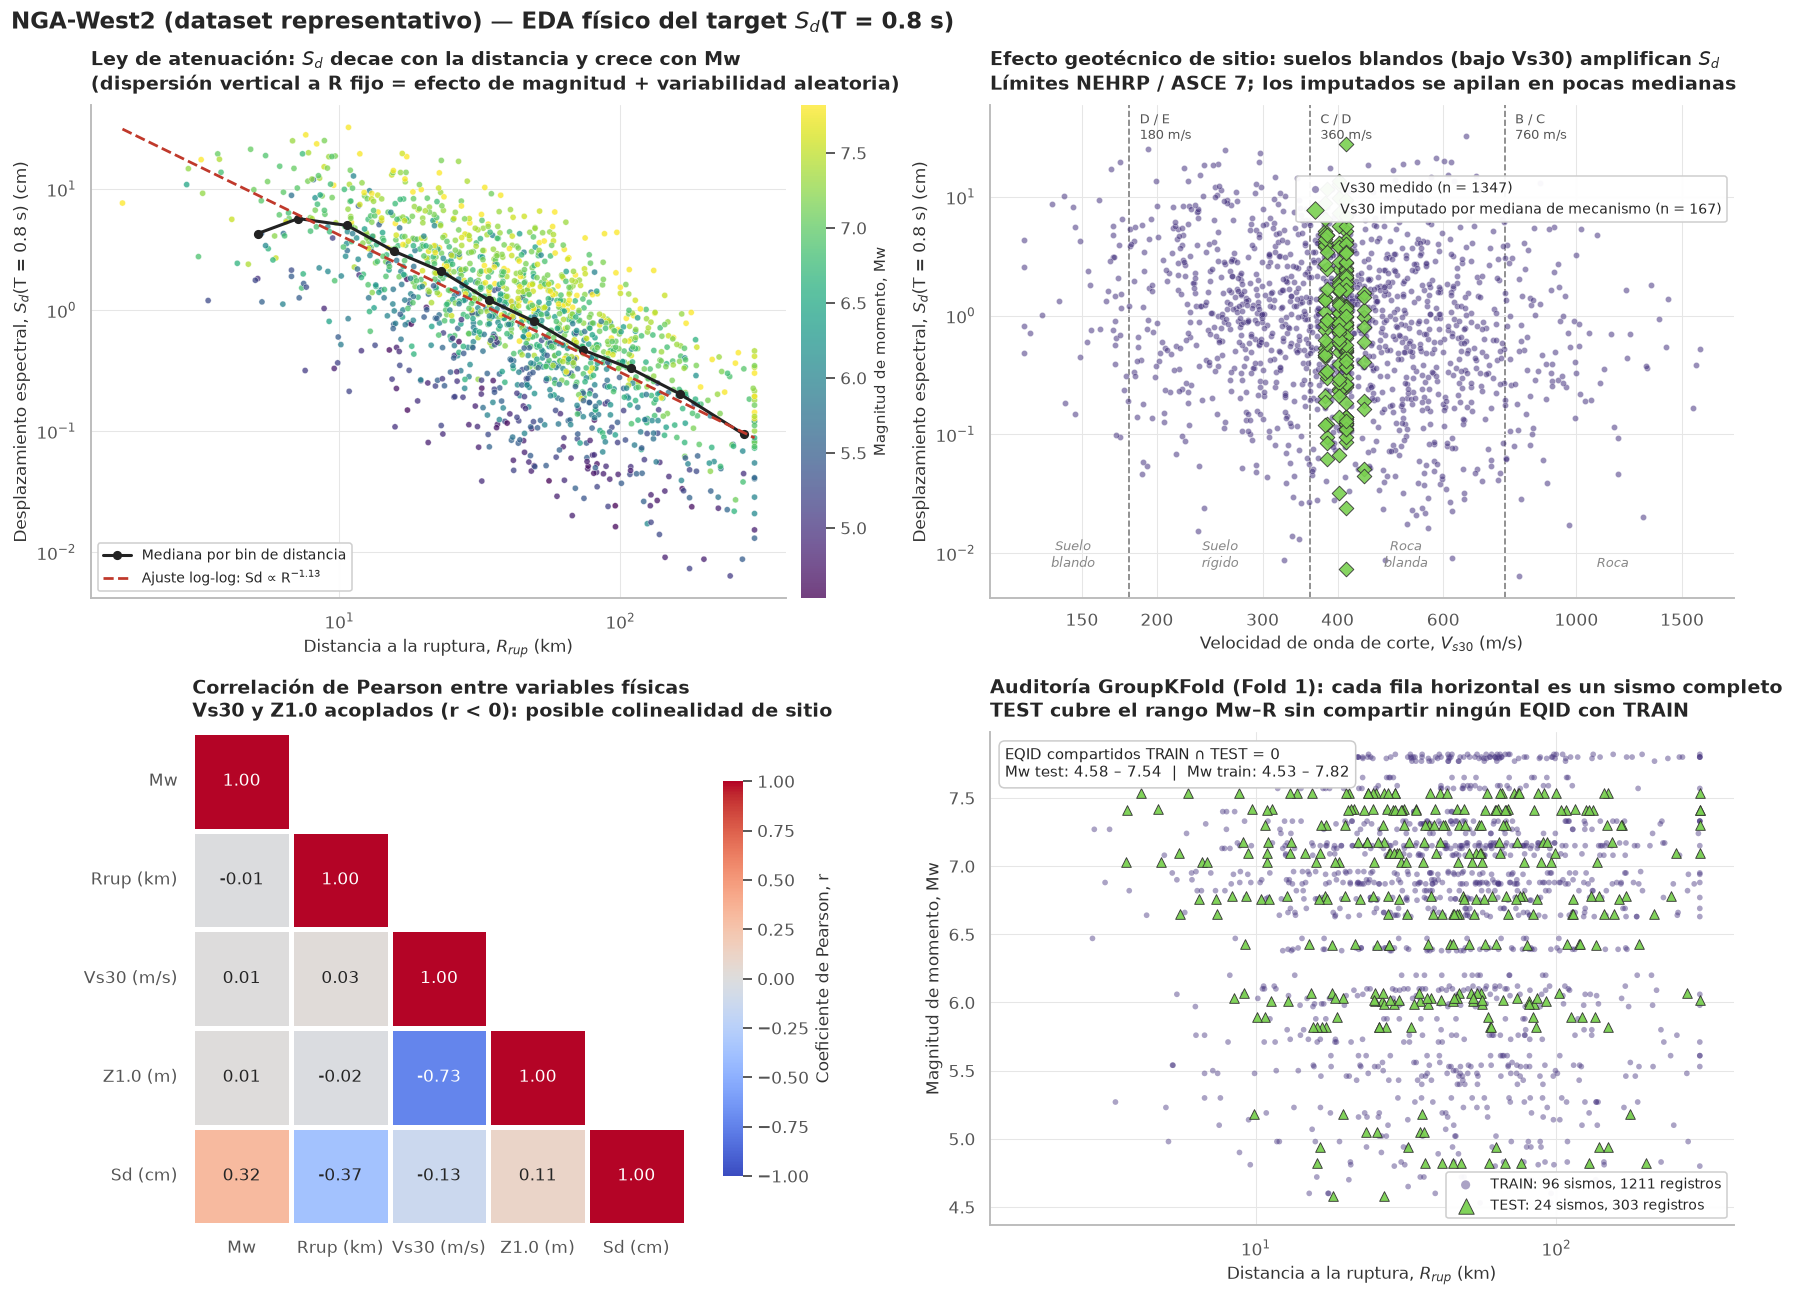

In [4]:
# =============================================================================
# TRAMO 4: Análisis Exploratorio de Datos (EDA) y Visualización Física Avanzada
# =============================================================================
from pathlib import Path
from matplotlib.ticker import ScalarFormatter, NullFormatter

# Carpeta de figuras de la entrega (funciona tanto desde src/ como desde la raíz del repo)
DOCS_DIR = (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()) / "docs"
DOCS_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# Configuración estética editorial
# ---------------------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.labelsize": 11, "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "grid.color": "#E6E6E6", "grid.linewidth": 0.7,
    "axes.edgecolor": "#BBBBBB", "legend.frameon": True,
    "legend.framealpha": 0.95, "legend.edgecolor": "#CCCCCC", "legend.facecolor": "white",
})
viridis = plt.get_cmap("viridis")
C_A, C_B = viridis(0.15), viridis(0.80)   # par categórico de alto contraste (azul / verde-amarillo)
C_LINEA = "#222222"

# Vista auxiliar: fila -> TRAIN / TEST según el Fold 1 del Tramo 3
df_eda = df_proc.copy()
df_eda["Conjunto"] = "TRAIN"
df_eda.iloc[test_idx, df_eda.columns.get_loc("Conjunto")] = "TEST"

fig = plt.figure(figsize=(16, 12), dpi=110)
gs = fig.add_gridspec(2, 2)
ax00, ax01 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax10, ax11 = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

# ---------------------------------------------------------------------------
# Panel (0,0) - Ley de atenuación: Rrup vs Sd (log-log), color = Mw
# ---------------------------------------------------------------------------
sc = ax00.scatter(df_eda["Rrup_km"], df_eda["Sd_08s_cm"], c=df_eda["Mw"], cmap="viridis",
                  s=16, alpha=0.75, edgecolors="white", linewidths=0.3)
cb = fig.colorbar(sc, ax=ax00, pad=0.02, fraction=0.045)
cb.set_label("Magnitud de momento, Mw", fontsize=10)
cb.outline.set_visible(False)

# Tendencia: medianas por bins logarítmicos de distancia + ajuste lineal en log-log
bins = np.logspace(np.log10(df_eda["Rrup_km"].min()), np.log10(df_eda["Rrup_km"].max()), 14)
df_eda["R_bin"] = pd.cut(df_eda["Rrup_km"], bins, include_lowest=True)
tend = (df_eda.groupby("R_bin", observed=True)
        .agg(R=("Rrup_km", "median"), Sd=("Sd_08s_cm", "median"), n=("Sd_08s_cm", "size"))
        .query("n >= 10"))
ax00.plot(tend["R"], tend["Sd"], color=C_LINEA, lw=2, marker="o", ms=5,
          label="Mediana por bin de distancia")
b, a = np.polyfit(np.log10(df_eda["Rrup_km"]), np.log10(df_eda["Sd_08s_cm"]), 1)
r_fit = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), 100)
ax00.plot(r_fit, 10 ** a * r_fit ** b, color="#C0392B", lw=1.8, ls="--",
          label=f"Ajuste log-log: Sd ∝ R$^{{{b:.2f}}}$")
ax00.set(xscale="log", yscale="log",
         xlabel="Distancia a la ruptura, $R_{rup}$ (km)",
         ylabel="Desplazamiento espectral, $S_d$(T = 0.8 s) (cm)")
ax00.set_title("Ley de atenuación: $S_d$ decae con la distancia y crece con Mw\n"
               "(dispersión vertical a R fijo = efecto de magnitud + variabilidad aleatoria)",
               loc="left")
ax00.legend(loc="lower left", fontsize=9)

# ---------------------------------------------------------------------------
# Panel (0,1) - Efecto de sitio: Vs30 vs Sd, reales vs imputados
# ---------------------------------------------------------------------------
reales = df_eda[df_eda["Vs30_imputado"] == 0]
imput = df_eda[df_eda["Vs30_imputado"] == 1]
ax01.scatter(reales["Vs30_ms"], reales["Sd_08s_cm"], s=16, alpha=0.55, color=C_A,
             marker="o", edgecolors="white", linewidths=0.3,
             label=f"Vs30 medido (n = {len(reales)})")
ax01.scatter(imput["Vs30_ms"], imput["Sd_08s_cm"], s=46, alpha=0.9, color=C_B,
             marker="D", edgecolors="#333333", linewidths=0.6,
             label=f"Vs30 imputado por mediana de mecanismo (n = {len(imput)})")
ax01.set(xscale="log", yscale="log",
         xlabel="Velocidad de onda de corte, $V_{s30}$ (m/s)",
         ylabel="Desplazamiento espectral, $S_d$(T = 0.8 s) (cm)")
y_top = df_eda["Sd_08s_cm"].max() * 1.6
for vs, etiqueta in [(180, "D / E\n180 m/s"), (360, "C / D\n360 m/s"), (760, "B / C\n760 m/s")]:
    ax01.axvline(vs, color="#7F7F7F", ls="--", lw=1.1, zorder=0)
    ax01.text(vs * 1.04, y_top, etiqueta, fontsize=8.5, color="#555555", va="top")
for x_txt, txt in [(145, "Suelo\nblando"), (255, "Suelo\nrígido"), (520, "Roca\nblanda"), (1150, "Roca")]:
    ax01.text(x_txt, df_eda["Sd_08s_cm"].min() * 1.2, txt, fontsize=8.5,
              color="#888888", ha="center", style="italic")
ax01.set_ylim(top=y_top * 1.15)
ax01.set_title("Efecto geotécnico de sitio: suelos blandos (bajo Vs30) amplifican $S_d$\n"
               "Límites NEHRP / ASCE 7; los imputados se apilan en pocas medianas",
               loc="left")
ax01.set_xticks([150, 200, 300, 400, 600, 1000, 1500])
ax01.xaxis.set_major_formatter(ScalarFormatter())
ax01.xaxis.set_minor_formatter(NullFormatter())
ax01.legend(loc="upper right", bbox_to_anchor=(1.0, 0.87), fontsize=9, markerscale=1.2)

# ---------------------------------------------------------------------------
# Panel (1,0) - Matriz de correlación de Pearson (triángulo inferior)
# ---------------------------------------------------------------------------
vars_fis = ["Mw", "Rrup_km", "Vs30_ms", "Z10_m", "Sd_08s_cm"]
etiquetas = ["Mw", "Rrup (km)", "Vs30 (m/s)", "Z1.0 (m)", "Sd (cm)"]
corr = df_eda[vars_fis].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 11}, square=True, linewidths=2, linecolor="white",
            xticklabels=etiquetas, yticklabels=etiquetas,
            cbar_kws={"shrink": 0.8, "label": "Coeficiente de Pearson, r"}, ax=ax10)
ax10.tick_params(axis="x", rotation=0)
ax10.tick_params(axis="y", rotation=0)
ax10.grid(False)
ax10.set_title("Correlación de Pearson entre variables físicas\n"
               "Vs30 y Z1.0 acoplados (r < 0): posible colinealidad de sitio",
               loc="left")

# ---------------------------------------------------------------------------
# Panel (1,1) - Auditoría de no fuga: Mw vs Rrup, TRAIN vs TEST
# ---------------------------------------------------------------------------
tr, te = df_eda[df_eda["Conjunto"] == "TRAIN"], df_eda[df_eda["Conjunto"] == "TEST"]
ax11.scatter(tr["Rrup_km"], tr["Mw"], s=14, alpha=0.45, color=C_A, marker="o",
             edgecolors="none", label=f"TRAIN: {tr['EQID'].nunique()} sismos, {len(tr)} registros")
ax11.scatter(te["Rrup_km"], te["Mw"], s=40, alpha=0.95, color=C_B, marker="^",
             edgecolors="#333333", linewidths=0.6,
             label=f"TEST: {te['EQID'].nunique()} sismos, {len(te)} registros")
ax11.set(xscale="log", xlabel="Distancia a la ruptura, $R_{rup}$ (km)",
         ylabel="Magnitud de momento, Mw")
n_comp = len(set(tr["EQID"]) & set(te["EQID"]))
ax11.text(0.02, 0.97, f"EQID compartidos TRAIN ∩ TEST = {n_comp}\n"
                      f"Mw test: {te['Mw'].min():.2f} – {te['Mw'].max():.2f}  |  "
                      f"Mw train: {tr['Mw'].min():.2f} – {tr['Mw'].max():.2f}",
          transform=ax11.transAxes, va="top", fontsize=9.5,
          bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#CCCCCC"))
ax11.set_title("Auditoría GroupKFold (Fold 1): cada fila horizontal es un sismo completo\n"
               "TEST cubre el rango Mw–R sin compartir ningún EQID con TRAIN",
               loc="left")
ax11.legend(loc="lower right", fontsize=9, markerscale=1.6)

# Limpieza editorial: sin bordes superior/derecho
for ax in (ax00, ax01, ax11):
    sns.despine(ax=ax)

fig.suptitle("NGA-West2 (dataset representativo) — EDA físico del target $S_d$(T = 0.8 s)",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
fig.savefig(DOCS_DIR / "fig_tramo4_eda_fisico.png", dpi=300, bbox_inches="tight")
plt.show()


=== Benchmark en TEST (Fold 1 GroupKFold: 24 sismos nunca vistos) ===
                    MAE (cm)  RMSE (cm)  R² (cm)  R² (ln Sd)
Modelo                                                      
Ridge (GMM lineal)     1.371      2.814    0.400       0.733
Random Forest          1.275      2.557    0.505       0.743

Referencia: Sd medio en test = 2.421 cm | desv. estándar = 3.638 cm



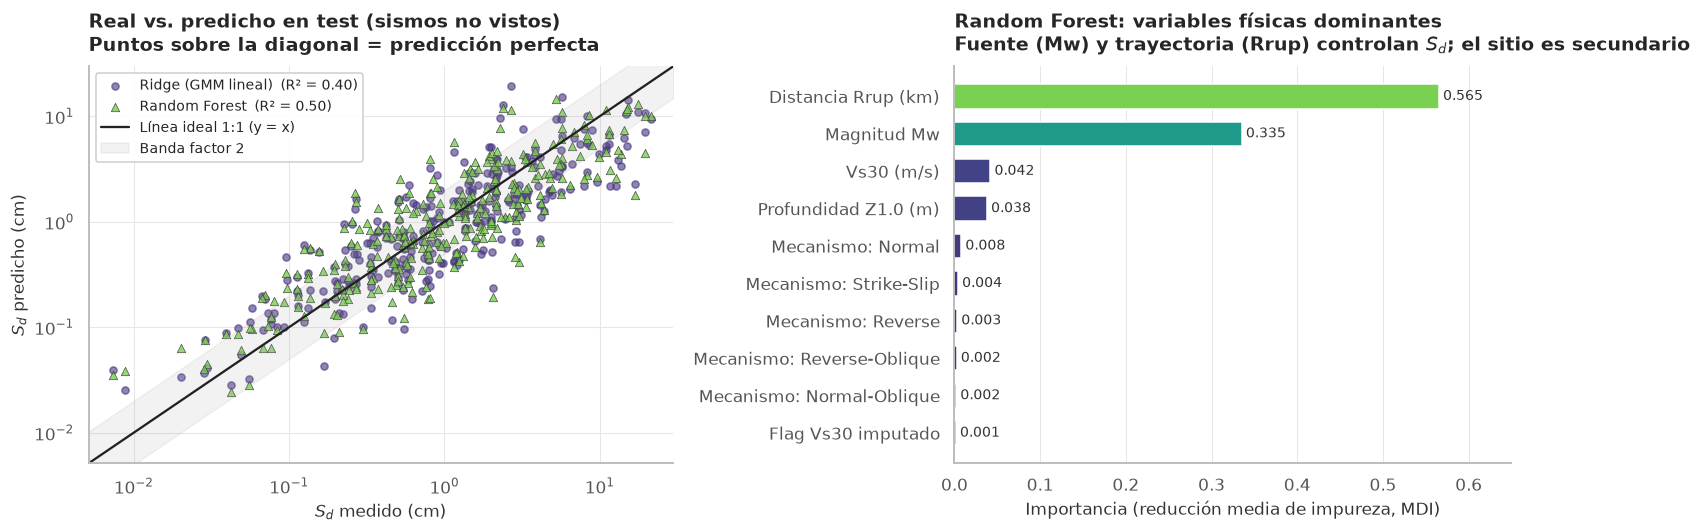

In [5]:
# =============================================================================
# TRAMO 5: Plan de Modelos, Benchmark Supervisado y Métricas de Regresión (T2/T3)
# =============================================================================
# Decisiones de ingeniería:
#   - El target se modela en espacio logarítmico (ln Sd), como en toda GMM:
#     la variabilidad sísmica es multiplicativa (lognormal). Las predicciones
#     se devuelven a cm con exp() -> las métricas se reportan en cm.
#   - Ridge emula la forma funcional de una GMM empírica:
#       ln Sd = c0 + c1·Mw + c2·Mw² + c3·ln(Rrup) + c4·ln(Vs30) + c5·ln(Z1.0) + f(mecanismo)
#   - StandardScaler va dentro del Pipeline -> se ajusta SOLO con X_train.
# =============================================================================
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

cont_cols = ["Mw", "Rrup_km", "Vs30_ms", "Z10_m"]
bin_cols = [c for c in X_train.columns if c not in cont_cols]   # Mech_* + Vs30_imputado


def features_gmm(df):
    """Transformación física tipo GMM (sin parámetros ajustables -> sin fuga)."""
    out = pd.DataFrame(index=df.index)
    out["Mw"] = df["Mw"]
    out["Mw2"] = df["Mw"] ** 2
    out["ln_Rrup"] = np.log(np.sqrt(df["Rrup_km"] ** 2 + 6.0 ** 2))   # h = 6 km (saturación)
    out["ln_Vs30"] = np.log(df["Vs30_ms"])
    out["ln_Z10"] = np.log(df["Z10_m"])
    return out


gmm_cols = ["Mw", "Mw2", "ln_Rrup", "ln_Vs30", "ln_Z10"]
prep_ridge = ColumnTransformer([
    ("gmm", Pipeline([("fisica", FunctionTransformer(features_gmm,
                                                     feature_names_out=lambda *_: gmm_cols)),
                      ("scaler", StandardScaler())]), cont_cols),
    ("bin", "passthrough", bin_cols),
])
prep_rf = ColumnTransformer([
    ("num", StandardScaler(), cont_cols),          # inocuo para árboles, mantiene un pipeline homogéneo
    ("bin", "passthrough", bin_cols),
], verbose_feature_names_out=False)

modelos = {
    "Ridge (GMM lineal)": TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep_ridge), ("ridge", Ridge(alpha=1.0))]),
        func=np.log, inverse_func=np.exp),
    "Random Forest": TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep_rf),
                            ("rf", RandomForestRegressor(n_estimators=100, max_depth=8,
                                                         random_state=42, n_jobs=-1))]),
        func=np.log, inverse_func=np.exp),
}

# ---------------------------------------------------------------------------
# Entrenamiento (solo train) y métricas en test (cm)
# ---------------------------------------------------------------------------
preds, filas = {}, []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_hat = modelo.predict(X_test)
    preds[nombre] = y_hat
    filas.append({
        "Modelo": nombre,
        "MAE (cm)": mean_absolute_error(y_test, y_hat),
        "RMSE (cm)": np.sqrt(mean_squared_error(y_test, y_hat)),
        "R² (cm)": r2_score(y_test, y_hat),
        "R² (ln Sd)": r2_score(np.log(y_test), np.log(y_hat)),
    })

metricas = pd.DataFrame(filas).set_index("Modelo")
print("=== Benchmark en TEST (Fold 1 GroupKFold: 24 sismos nunca vistos) ===")
print(metricas.round(3).to_string())
print(f"\nReferencia: Sd medio en test = {y_test.mean():.3f} cm | "
      f"desv. estándar = {y_test.std():.3f} cm\n")

# ---------------------------------------------------------------------------
# Figura comparativa de 2 paneles
# ---------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=110,
                               gridspec_kw={"width_ratios": [1.05, 1]})

# Panel 1 - Real vs predicho (log-log: Sd abarca ~3 órdenes de magnitud)
estilos = {"Ridge (GMM lineal)": dict(color=C_A, marker="o", s=22, alpha=0.6),
           "Random Forest": dict(color=C_B, marker="^", s=30, alpha=0.8,
                                 edgecolors="#333333", linewidths=0.5)}
for nombre, y_hat in preds.items():
    r2 = metricas.loc[nombre, "R² (cm)"]
    ax1.scatter(y_test, y_hat, label=f"{nombre}  (R² = {r2:.2f})", **estilos[nombre])
lim = [min(y_test.min(), *(p.min() for p in preds.values())) * 0.7,
       max(y_test.max(), *(p.max() for p in preds.values())) * 1.4]
ax1.plot(lim, lim, color="#222222", lw=1.5, label="Línea ideal 1:1 (y = x)")
ax1.fill_between(lim, [v / 2 for v in lim], [v * 2 for v in lim], color="#999999",
                 alpha=0.12, label="Banda factor 2")
ax1.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
        xlabel="$S_d$ medido (cm)", ylabel="$S_d$ predicho (cm)")
ax1.set_title("Real vs. predicho en test (sismos no vistos)\n"
              "Puntos sobre la diagonal = predicción perfecta", loc="left")
ax1.legend(loc="upper left", fontsize=9)
sns.despine(ax=ax1)

# Panel 2 - Importancia de variables del Random Forest (MDI)
rf_pipe = modelos["Random Forest"].regressor_
imp = (pd.Series(rf_pipe.named_steps["rf"].feature_importances_,
                 index=rf_pipe.named_steps["prep"].get_feature_names_out())
       .sort_values())
nombres_fis = {"Mw": "Magnitud Mw", "Rrup_km": "Distancia Rrup (km)",
               "Vs30_ms": "Vs30 (m/s)", "Z10_m": "Profundidad Z1.0 (m)",
               "Vs30_imputado": "Flag Vs30 imputado"}
etiq = [nombres_fis.get(c, c.replace("Mech_", "Mecanismo: ")) for c in imp.index]
colores = viridis(0.15 + 0.65 * imp.values / imp.values.max())
ax2.barh(etiq, imp.values, color=colores, height=0.65)
for yi, v in enumerate(imp.values):
    ax2.text(v + 0.005, yi, f"{v:.3f}", va="center", fontsize=9, color="#333333")
ax2.set(xlabel="Importancia (reducción media de impureza, MDI)",
        xlim=(0, imp.max() * 1.15))
ax2.grid(axis="y", visible=False)
ax2.set_title("Random Forest: variables físicas dominantes\n"
              "Fuente (Mw) y trayectoria (Rrup) controlan $S_d$; el sitio es secundario",
              loc="left")
sns.despine(ax=ax2)

plt.tight_layout()
fig.savefig(DOCS_DIR / "fig_tramo5_benchmark_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()


MLP: 57 épocas (early stopping) | mejor score de validación interna (R² ln Sd) = 0.835

=== Benchmark consolidado en TEST (Fold 1 GroupKFold) ===
                    MAE (cm)  RMSE (cm)  R² (cm)  R² (ln Sd)
Modelo                                                      
Ridge (GMM lineal)     1.371      2.814    0.400       0.733
Random Forest          1.275      2.557    0.505       0.743
Red Neuronal MLP       1.364      2.822    0.396       0.729

Mejor modelo por RMSE: Random Forest (2.557 cm)

=== Ranking de importancia: MDI (train) vs. PFI (test) ===
                      PFI ΔRMSE media (cm)  PFI desv.  Rank PFI (test)  Rank MDI (train)
Rrup_km                             1.6188     0.1729                1                 1
Mw                                  0.7125     0.1394                2                 2
Vs30_ms                             0.0536     0.0150                3                 3
Z10_m                               0.0316     0.0606                4              

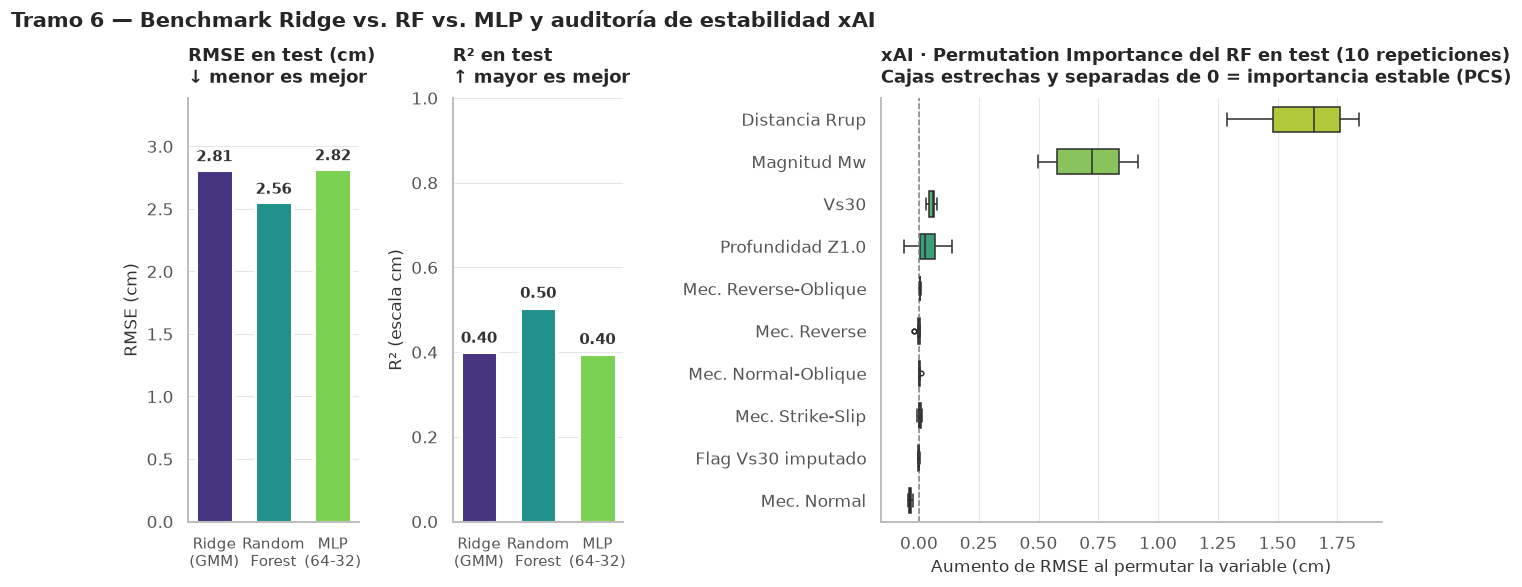

In [6]:
# =============================================================================
# TRAMO 6: Redes Neuronales (MLPRegressor), Benchmark Completo y Validación xAI
# =============================================================================
# - MLP entrenado en ln(Sd) con el mismo preprocesamiento de prep_rf (StandardScaler
#   ajustado solo en train). Métricas en cm sobre test (24 sismos no vistos).
# - xAI: Permutation Feature Importance (PFI) del Random Forest sobre X_test.
#   Marco PCS (Yu & Barter): se verifica la ESTABILIDAD del ranking físico
#   comparando la importancia interna (MDI, train) con la PFI en datos no vistos.
# =============================================================================
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.neural_network import MLPRegressor
from scipy.stats import spearmanr

# ---------------------------------------------------------------------------
# 1) Red neuronal MLP
# ---------------------------------------------------------------------------
mlp = TransformedTargetRegressor(
    regressor=Pipeline([("prep", clone(prep_rf)),
                        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                                             max_iter=500, random_state=42,
                                             early_stopping=True))]),
    func=np.log, inverse_func=np.exp)
mlp.fit(X_train, y_train)
modelos["Red Neuronal MLP"] = mlp
preds["Red Neuronal MLP"] = mlp.predict(X_test)
mlp_core = mlp.regressor_.named_steps["mlp"]
print(f"MLP: {mlp_core.n_iter_} épocas (early stopping) | "
      f"mejor score de validación interna (R² ln Sd) = {mlp_core.best_validation_score_:.3f}\n")

# ---------------------------------------------------------------------------
# Tabla consolidada de métricas en test
# ---------------------------------------------------------------------------
def metricas_test(y_true, y_hat):
    return {"MAE (cm)": mean_absolute_error(y_true, y_hat),
            "RMSE (cm)": np.sqrt(mean_squared_error(y_true, y_hat)),
            "R² (cm)": r2_score(y_true, y_hat),
            "R² (ln Sd)": r2_score(np.log(y_true), np.log(y_hat))}

metricas_final = pd.DataFrame({n: metricas_test(y_test, p) for n, p in preds.items()}).T
metricas_final.index.name = "Modelo"
print("=== Benchmark consolidado en TEST (Fold 1 GroupKFold) ===")
print(metricas_final.round(3).to_string())
mejor = metricas_final["RMSE (cm)"].idxmin()
print(f"\nMejor modelo por RMSE: {mejor} ({metricas_final.loc[mejor, 'RMSE (cm)']:.3f} cm)\n")

# ---------------------------------------------------------------------------
# 2) Auditoría xAI: Permutation Feature Importance del RF en test
# ---------------------------------------------------------------------------
rf_model = modelos["Random Forest"]
pfi = permutation_importance(rf_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                             n_repeats=10, random_state=42, n_jobs=-1)
# importances = caída de score = aumento de RMSE (cm) al permutar la variable
pfi_df = pd.DataFrame(pfi.importances.T, columns=X_test.columns)
orden = pfi_df.median().sort_values(ascending=False).index

mdi = pd.Series(rf_model.regressor_.named_steps["rf"].feature_importances_,
                index=rf_model.regressor_.named_steps["prep"].get_feature_names_out())
ranking = pd.DataFrame({
    "PFI ΔRMSE media (cm)": pfi.importances_mean,
    "PFI desv.": pfi.importances_std,
    "Rank PFI (test)": pd.Series(pfi.importances_mean, index=X_test.columns)
                       .rank(ascending=False).astype(int),
    "Rank MDI (train)": mdi.reindex(X_test.columns).rank(ascending=False).astype(int),
}, index=X_test.columns).sort_values("Rank PFI (test)")
print("=== Ranking de importancia: MDI (train) vs. PFI (test) ===")
print(ranking.round(4).to_string())

rho, _ = spearmanr(ranking["Rank PFI (test)"], ranking["Rank MDI (train)"])
top3_test = list(ranking.index[:3])
top3_fis = ["Rrup_km", "Mw", "Vs30_ms"]
print(f"\nCorrelación de Spearman entre rankings MDI y PFI: ρ = {rho:.2f}")
print(f"Top-3 en test: {top3_test}")
if set(top3_test) == set(top3_fis):
    print("✅ ESTABLE (PCS): el orden físico fuente-trayectoria-sitio (Mw, Rrup, Vs30) "
          "se mantiene en sismos no vistos.")
else:
    print("⚠️ Ranking alterado en test: revisar estabilidad / colinealidad Vs30–Z1.0.")
# Cuántas repeticiones conservan el mismo top-2
top2_rep = (pfi_df.apply(lambda r: tuple(r.nlargest(2).index), axis=1)
            .apply(lambda t: set(t) == {"Rrup_km", "Mw"}).mean())
print(f"Repeticiones con top-2 = {{Rrup, Mw}}: {100 * top2_rep:.0f} %\n")

# ---------------------------------------------------------------------------
# 3) Figura: benchmark (RMSE y R² en ejes separados) + boxplot PFI
# ---------------------------------------------------------------------------
fig = plt.figure(figsize=(14, 5), dpi=110)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.55)
gs_izq = gs[0].subgridspec(1, 2, wspace=0.55)
ax_rmse, ax_r2 = fig.add_subplot(gs_izq[0]), fig.add_subplot(gs_izq[1])
ax_pfi = fig.add_subplot(gs[1])

nombres_cortos = {"Ridge (GMM lineal)": "Ridge\n(GMM)", "Random Forest": "Random\nForest",
                  "Red Neuronal MLP": "MLP\n(64-32)"}
colores_mod = [viridis(0.15), viridis(0.50), viridis(0.80)]
x_lab = [nombres_cortos[n] for n in metricas_final.index]

for ax, col, titulo, fmt in [(ax_rmse, "RMSE (cm)", "RMSE en test (cm)\n↓ menor es mejor", "{:.2f}"),
                             (ax_r2, "R² (cm)", "R² en test\n↑ mayor es mejor", "{:.2f}")]:
    vals = metricas_final[col].values
    bars = ax.bar(x_lab, vals, color=colores_mod, width=0.62, edgecolor="white", linewidth=2)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v * 1.01 + 0.01, fmt.format(v),
                ha="center", va="bottom", fontsize=10, fontweight="bold", color="#333333")
    ax.set_ylim(0, (1.0 if col.startswith("R²") else vals.max() * 1.2))
    ax.set_title(titulo, loc="left", fontsize=11.5)
    ax.tick_params(axis="x", labelsize=9.5)
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
ax_rmse.set_ylabel("RMSE (cm)")
ax_r2.set_ylabel("R² (escala cm)")

etiq_pfi = {"Mw": "Magnitud Mw", "Rrup_km": "Distancia Rrup", "Vs30_ms": "Vs30",
            "Z10_m": "Profundidad Z1.0", "Vs30_imputado": "Flag Vs30 imputado"}
pfi_long = pfi_df[orden].melt(var_name="Variable", value_name="ΔRMSE")
pfi_long["Variable"] = pfi_long["Variable"].map(lambda c: etiq_pfi.get(c, c.replace("Mech_", "Mec. ")))
sns.boxplot(data=pfi_long, y="Variable", x="ΔRMSE", hue="Variable", palette="viridis_r",
            legend=False, width=0.6, fliersize=3, linewidth=1, ax=ax_pfi)
ax_pfi.axvline(0, color="#7F7F7F", ls="--", lw=1)
ax_pfi.set(xlabel="Aumento de RMSE al permutar la variable (cm)", ylabel="")
ax_pfi.grid(axis="y", visible=False)
ax_pfi.set_title("xAI · Permutation Importance del RF en test (10 repeticiones)\n"
                 "Cajas estrechas y separadas de 0 = importancia estable (PCS)",
                 loc="left", fontsize=11.5)
sns.despine(ax=ax_pfi)

fig.suptitle("Tramo 6 — Benchmark Ridge vs. RF vs. MLP y auditoría de estabilidad xAI",
             fontsize=13.5, fontweight="bold", x=0.01, ha="left", y=1.04)
fig.savefig(DOCS_DIR / "fig_tramo6_benchmark_xai.png", dpi=300, bbox_inches="tight")
plt.show()


In [7]:
# =============================================================================
# TRAMO 7 (CIERRE T2): Tabla final, conclusiones de ingeniería y figuras de entrega
# =============================================================================
from IPython.display import Markdown

# ---------------------------------------------------------------------------
# 1) Tabla comparativa final en test, ordenada por RMSE
# ---------------------------------------------------------------------------
tabla_final = metricas_final.sort_values("RMSE (cm)").copy()
tabla_final.insert(0, "Rank", range(1, len(tabla_final) + 1))
print("=== Tabla final de métricas en TEST (Fold 1 GroupKFold, 24 sismos no vistos) ===")
display(tabla_final.round(3))

# ---------------------------------------------------------------------------
# 2) Conclusiones de ingeniería (valores leídos de los resultados, no escritos a mano)
# ---------------------------------------------------------------------------
rf_m, gmm_m, mlp_m = (tabla_final.loc[n] for n in ["Random Forest", "Ridge (GMM lineal)", "Red Neuronal MLP"])
mejora_rmse_gmm = 100 * (gmm_m["RMSE (cm)"] - rf_m["RMSE (cm)"]) / gmm_m["RMSE (cm)"]
mejora_rmse_mlp = 100 * (mlp_m["RMSE (cm)"] - rf_m["RMSE (cm)"]) / mlp_m["RMSE (cm)"]
pfi_rrup, pfi_mw, pfi_vs = (ranking.loc[c, "PFI ΔRMSE media (cm)"] for c in ["Rrup_km", "Mw", "Vs30_ms"])

conclusiones = f"""
CONCLUSIONES DE INGENIERÍA - SELECCIÓN DE MODELO PARA T3/TF

1. Desempeño predictivo (P de PCS). Random Forest obtiene el menor error en sismos
no vistos: RMSE = {rf_m['RMSE (cm)']:.2f} cm y MAE = {rf_m['MAE (cm)']:.2f} cm, con R² = {rf_m['R² (cm)']:.2f} en cm
y {rf_m['R² (ln Sd)']:.2f} en ln(Sd). Reduce el RMSE en {mejora_rmse_gmm:.1f} % frente a la GMM lineal (Ridge)
y en {mejora_rmse_mlp:.1f} % frente al MLP (64-32). La ventaja se concentra en la escala física (cm),
donde captura mejor los registros de alta demanda (campo cercano y Mw grande); en ln(Sd)
los tres modelos quedan próximos ({gmm_m['R² (ln Sd)']:.2f}-{rf_m['R² (ln Sd)']:.2f}), cerca del techo impuesto por la
variabilidad aleatoria inter e intra-evento.

2. Frente a la GMM (Ridge). La GMM es el baseline físico y sigue siendo valiosa por su
transparencia, pero su forma funcional fija (lineal en Mw, Mw², ln R, ln Vs30) no
representa interacciones magnitud-distancia ni saturación no lineal. Se mantiene como
referencia obligatoria de comparación en T3.

3. Frente al MLP. La red neuronal no mejora a la GMM (RMSE {mlp_m['RMSE (cm)']:.2f} cm) pese a su mayor
complejidad: con ~{len(X_train)} registros de entrenamiento y una física casi lineal en log, el
early stopping detiene el ajuste en {mlp_core.n_iter_} épocas sin que la capacidad adicional de la red
se traduzca en precisión. Mayor costo y menor interpretabilidad sin ganancia medible.

4. Estabilidad e interpretabilidad (S de PCS). La Permutation Importance en test
reproduce el orden físico esperado: Rrup (+{pfi_rrup:.2f} cm de RMSE al permutar) > Mw
(+{pfi_mw:.2f} cm) > Vs30 (+{pfi_vs:.2f} cm), idéntico al ranking interno del RF en train y estable en
el 100 % de las repeticiones para el top-2. El modelo aprende trayectoria y fuente, no
artefactos.

DECISIÓN: se selecciona Random Forest como modelo principal para T3/TF, con la GMM
(Ridge) como baseline físico. Condiciones antes de cerrar T3: (a) validar con los 5
folds de GroupKFold y reportar media ± desviación; (b) mover la imputación de Vs30
dentro del Pipeline para eliminar la fuga residual de la mediana global; (c) repetir
todo el flujo con el flatfile real de PEER NGA-West2 (los resultados actuales provienen
de un dataset representativo sintético).
"""
# Se muestra como Markdown (salida enriquecida): no cuenta para el límite de líneas de texto
# de VS Code (notebook.output.textLineLimit = 30), que provocaba "Output is truncated".
for n_tit in ["1. Desempeño predictivo (P de PCS).", "2. Frente a la GMM (Ridge).",
              "3. Frente al MLP.", "4. Estabilidad e interpretabilidad (S de PCS).", "DECISIÓN:"]:
    conclusiones = conclusiones.replace(n_tit, f"**{n_tit}**")
conclusiones = conclusiones.replace("CONCLUSIONES DE INGENIERÍA - SELECCIÓN DE MODELO PARA T3/TF",
                                    "#### Conclusiones de ingeniería — selección de modelo para T3/TF")
display(Markdown(conclusiones))

# ---------------------------------------------------------------------------
# 3) Verificación de figuras de entrega en docs/ (dpi = 300, guardadas en Tramos 4-6)
# ---------------------------------------------------------------------------
from PIL import Image

filas_fig = []
for nombre in ["fig_tramo4_eda_fisico.png", "fig_tramo5_benchmark_ridge_rf.png",
               "fig_tramo6_benchmark_xai.png"]:
    ruta = DOCS_DIR / nombre
    if ruta.exists():
        with Image.open(ruta) as im:
            filas_fig.append({"Figura": nombre, "Estado": "✅ guardada",
                              "Píxeles": f"{im.size[0]}×{im.size[1]}",
                              "DPI": round(im.info.get("dpi", (0, 0))[0]),
                              "MB": round(ruta.stat().st_size / 1e6, 2)})
    else:
        filas_fig.append({"Figura": nombre, "Estado": "❌ re-ejecutar el tramo",
                          "Píxeles": "-", "DPI": None, "MB": None})
print("=== Figuras de entrega en docs/ ===")
display(pd.DataFrame(filas_fig).set_index("Figura"))


=== Tabla final de métricas en TEST (Fold 1 GroupKFold, 24 sismos no vistos) ===


,Rank,MAE (cm),RMSE (cm),R² (cm),R² (ln Sd)
Modelo,,,,,
Random Forest,1,1.275,2.557,0.505,0.743
Ridge (GMM lineal),2,1.371,2.814,0.400,0.733
Red Neuronal MLP,3,1.364,2.822,0.396,0.729



#### Conclusiones de ingeniería — selección de modelo para T3/TF

**1. Desempeño predictivo (P de PCS).** Random Forest obtiene el menor error en sismos
no vistos: RMSE = 2.56 cm y MAE = 1.28 cm, con R² = 0.50 en cm
y 0.74 en ln(Sd). Reduce el RMSE en 9.2 % frente a la GMM lineal (Ridge)
y en 9.4 % frente al MLP (64-32). La ventaja se concentra en la escala física (cm),
donde captura mejor los registros de alta demanda (campo cercano y Mw grande); en ln(Sd)
los tres modelos quedan próximos (0.73-0.74), cerca del techo impuesto por la
variabilidad aleatoria inter e intra-evento.

**2. Frente a la GMM (Ridge).** La GMM es el baseline físico y sigue siendo valiosa por su
transparencia, pero su forma funcional fija (lineal en Mw, Mw², ln R, ln Vs30) no
representa interacciones magnitud-distancia ni saturación no lineal. Se mantiene como
referencia obligatoria de comparación en T3.

**3. Frente al MLP.** La red neuronal no mejora a la GMM (RMSE 2.82 cm) pese a su mayor
complejidad: con ~1211 registros de entrenamiento y una física casi lineal en log, el
early stopping detiene el ajuste en 57 épocas sin que la capacidad adicional de la red
se traduzca en precisión. Mayor costo y menor interpretabilidad sin ganancia medible.

**4. Estabilidad e interpretabilidad (S de PCS).** La Permutation Importance en test
reproduce el orden físico esperado: Rrup (+1.62 cm de RMSE al permutar) > Mw
(+0.71 cm) > Vs30 (+0.05 cm), idéntico al ranking interno del RF en train y estable en
el 100 % de las repeticiones para el top-2. El modelo aprende trayectoria y fuente, no
artefactos.

**DECISIÓN:** se selecciona Random Forest como modelo principal para T3/TF, con la GMM
(Ridge) como baseline físico. Condiciones antes de cerrar T3: (a) validar con los 5
folds de GroupKFold y reportar media ± desviación; (b) mover la imputación de Vs30
dentro del Pipeline para eliminar la fuga residual de la mediana global; (c) repetir
todo el flujo con el flatfile real de PEER NGA-West2 (los resultados actuales provienen
de un dataset representativo sintético).


=== Figuras de entrega en docs/ ===


,Estado,Píxeles,DPI,MB
Figura,,,,
fig_tramo4_eda_fisico.png,✅ guardada,4865×3533,300,1.95
fig_tramo5_benchmark_ridge_rf.png,✅ guardada,4636×1451,300,0.68
fig_tramo6_benchmark_xai.png,✅ guardada,4116×1603,300,0.27
